# AI Media Trend Mining
## Stage 2: Advanced Embedding Models Training and Analysis

**Authors:** Sever Alin, Huber Daniel & Girardin Robin  
**Affiliation:** Hochschule Luzern

---

In Stage 1 we explored and cleaned the AI Media Dataset, extracting entities, performing sentiment analysis, and constructing a knowledge graph. In this second stage we move to **representation learning**: training classical embeddings and fine-tuning a compact LLM on the corpus, then evaluating both approaches.

**Goals:**
- Load pre-processed Stage 1 data (already tokenized, stopwords removed, lemmatized)

- Fine-tune Qwen2.5-1.5B with LoRA

- Results

> **Environment:** Google Colab Pro (T4 or A100 GPU).


---
## 0 Environment Setup


In [3]:
!pip uninstall -y bitsandbytes
!pip install -q bitsandbytes==0.46.1
!pip install -q -U transformers accelerate peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 112.1 MB/s eta 0:00:00


In [4]:
%%capture
!pip -q install -U transformers datasets peft accelerate bitsandbytes evaluate scikit-learn pyarrow

In [5]:
import bitsandbytes as bnb
import transformers
import torch

print("bitsandbytes:", bnb.__version__)
print("transformers:", transformers.__version__)
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

bitsandbytes: 0.49.2
transformers: 5.3.0
torch: 2.10.0+cu128
CUDA available: True


In [6]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter


from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

import torch
print(f"PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

np.random.seed(42)
torch.manual_seed(42)


PyTorch: 2.10.0+cu128, CUDA: True
GPU: NVIDIA A100-SXM4-40GB


**MOUNT GOOGLE DRIVE**



In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AI-media-trend-mining_V2")
DATA_STAGE2 = PROJECT_DIR / "data" / "processed" / "stage_2"

TRAIN_PATH = DATA_STAGE2 / "llm_train.parquet"
TEST_PATH  = DATA_STAGE2 / "llm_test.parquet"

print("Train exists:", TRAIN_PATH.exists(), TRAIN_PATH)
print("Test exists: ", TEST_PATH.exists(), TEST_PATH)

Train exists: True /content/drive/MyDrive/AI-media-trend-mining_V2/data/processed/stage_2/llm_train.parquet
Test exists:  True /content/drive/MyDrive/AI-media-trend-mining_V2/data/processed/stage_2/llm_test.parquet


---
## 1 Load and inspect data

In [9]:
import pandas as pd

train_df = pd.read_parquet(TRAIN_PATH)
test_df  = pd.read_parquet(TEST_PATH)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

display(train_df.head(3))

Train shape: (13053, 6)
Test shape: (3264, 6)

Columns:
['media_id', 'full_content', 'sentiment_label', 'topic_id', 'topic_label', 'text']


,media_id,full_content,sentiment_label,topic_id,topic_label,text
0,3070,Their products transform masses of data into v...,neutral,0.0,AI News & Tech (General),### Instruction:\nYou are an AI media analyst....
1,9097,"In a recent article on Substack, Hollis Robbin...",neutral,NaN,None,### Instruction:\nYou are an AI media analyst....
2,13875,Epic Games took a big step with conversational...,neutral,NaN,None,### Instruction:\nYou are an AI media analyst....


### 1.1. Keep only rows with valid topic labels

In [10]:
train_df = train_df.dropna(subset=["topic_label"]).copy()
test_df  = test_df.dropna(subset=["topic_label"]).copy()

print("Train after topic filter:", train_df.shape)
print("Test after topic filter: ", test_df.shape)

print("\nTopic distribution in train:")
print(train_df["topic_label"].value_counts())

Train after topic filter: (8299, 6)
Test after topic filter:  (2037, 6)

Topic distribution in train:
topic_label
AI News & Tech (General)               4038
Search, SEO & Marketing                 813
Energy, Power & Robotics                681
ML Models & Training Data               646
Stocks & Market Ratings                 564
Quantum Computing                       418
US Politics & China Relations           410
AI in Media & Content                   278
AI in Education (Students/Learning)     232
Consumer Tech (Apple/5G/Devices)        219
Name: count, dtype: int64


### 1.2 Prepare data for topic

We will use 3 columns media_id, full_content and topic_label


In [11]:
train_df["model_text"] = train_df["full_content"].astype(str)
test_df["model_text"]  = test_df["full_content"].astype(str)

train_df = train_df[["media_id", "model_text", "topic_label"]].copy()
test_df  = test_df[["media_id", "model_text", "topic_label"]].copy()

display(train_df.head(3))


,media_id,model_text,topic_label
0,3070,Their products transform masses of data into v...,AI News & Tech (General)
3,13458,"As a Digiday+ member, you were able to access ...",AI in Media & Content
4,9106,Smart grids represent a transformative evoluti...,"Energy, Power & Robotics"


### 1.3 Encode topic labels

In [12]:
label_list = sorted(train_df["topic_label"].unique().tolist())
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}

train_df["label"] = train_df["topic_label"].map(label2id)
test_df["label"]  = test_df["topic_label"].map(label2id)

print("Number of classes:", len(label_list))
print("\nLabel mapping:")
for k, v in label2id.items():
    print(f"{v}: {k}")

Number of classes: 10

Label mapping:
0: AI News & Tech (General)
1: AI in Education (Students/Learning)
2: AI in Media & Content
3: Consumer Tech (Apple/5G/Devices)
4: Energy, Power & Robotics
5: ML Models & Training Data
6: Quantum Computing
7: Search, SEO & Marketing
8: Stocks & Market Ratings
9: US Politics & China Relations


### 1.4 validation split from train

Creating a validation split from the training set.


In [13]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["label"]
)

print("Train:", train_df.shape)
print("Val:  ", val_df.shape)
print("Test: ", test_df.shape)

Train: (7054, 4)
Val:   (1245, 4)
Test:  (2037, 4)


---
## 2 Convert to Hugging Face datasets

In [14]:
from datasets import Dataset, DatasetDict

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df[["model_text", "label"]], preserve_index=False),
    "validation": Dataset.from_pandas(val_df[["model_text", "label"]], preserve_index=False),
    "test": Dataset.from_pandas(test_df[["model_text", "label"]], preserve_index=False),
})

dataset

DatasetDict({
    train: Dataset({
        features: ['model_text', 'label'],
        num_rows: 7054
    })
    validation: Dataset({
        features: ['model_text', 'label'],
        num_rows: 1245
    })
    test: Dataset({
        features: ['model_text', 'label'],
        num_rows: 2037
    })
})

## 3 Load tokenizer and model

We will use the sequence-classification version of Qwen.

In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-1.5B"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)

model.config.pad_token_id = tokenizer.pad_token_id
print("Loaded model.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded model.


## 4 Add LoRA



In [16]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 2,194,432 || all params: 1,545,924,096 || trainable%: 0.1419


## 5 Tokenize


### 5.1 Inspect the text length distribution first

loading and filtering the topic rows.

In [17]:
import pandas as pd
import numpy as np
from transformers import AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-1.5B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# quick text stats using existing model_text
train_df["char_len"] = train_df["model_text"].astype(str).str.len()
train_df["word_len"] = train_df["model_text"].astype(str).str.split().str.len()

print("Character length summary:")
print(train_df["char_len"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

print("\nWord count summary:")
print(train_df["word_len"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

Character length summary:
count     7054.000000
mean      9257.367451
std       6053.397403
min        233.000000
50%       7282.000000
75%      10164.000000
90%      15008.100000
95%      20771.900000
99%      38282.690000
max      50325.000000
Name: char_len, dtype: float64

Word count summary:
count    7054.000000
mean     1448.591154
std       983.139891
min        32.000000
50%      1135.000000
75%      1599.750000
90%      2397.000000
95%      3305.050000
99%      5989.570000
max      9078.000000
Name: word_len, dtype: float64


compute actual token lengths on a sample first

In [18]:
sample_n = min(2000, len(train_df))
sample_df = train_df.sample(sample_n, random_state=42).copy()

def get_token_length(text):
    return len(tokenizer(str(text), truncation=False, add_special_tokens=True)["input_ids"])

sample_df["token_len"] = sample_df["model_text"].apply(get_token_length)

print("Token length summary on sample:")
print(sample_df["token_len"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

print("\nCoverage:")
for cutoff in [128, 256, 384, 512, 768]:
    pct = (sample_df["token_len"] <= cutoff).mean() * 100
    print(f"<= {cutoff:>3} tokens: {pct:6.2f}%")

Token length summary on sample:
count     2000.000000
mean      1828.607000
std       1276.828233
min         45.000000
50%       1431.500000
75%       1972.500000
90%       2943.700000
95%       4027.850000
99%       7666.470000
max      12432.000000
Name: token_len, dtype: float64

Coverage:
<= 128 tokens:   0.10%
<= 256 tokens:   0.30%
<= 384 tokens:   0.45%
<= 512 tokens:   0.50%
<= 768 tokens:   1.05%


simple chart

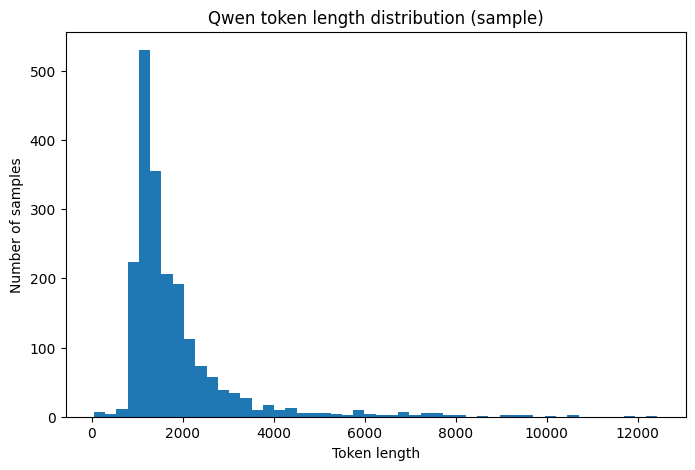

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(sample_df["token_len"], bins=50)
plt.xlabel("Token length")
plt.ylabel("Number of samples")
plt.title("Qwen token length distribution (sample)")
plt.show()

### 5.2 Choose max lenght


In [19]:
MAX_LENGTH = 512

def tokenize_function(examples):
    return tokenizer(
        examples["model_text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
    )

tokenized_dataset = dataset.map(tokenize_function, batched=True)
tokenized_dataset = tokenized_dataset.remove_columns(["model_text"])
tokenized_dataset.set_format("torch")

tokenized_dataset

Map:   0%|          | 0/7054 [00:00<?, ? examples/s]

Map:   0%|          | 0/1245 [00:00<?, ? examples/s]

Map:   0%|          | 0/2037 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 7054
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1245
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 2037
    })
})

## 6 Metrics


In [20]:
import evaluate
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_metric.compute(predictions=preds, references=labels)
    macro_f1 = f1_metric.compute(predictions=preds, references=labels, average="macro")

    return {
        "accuracy": acc["accuracy"],
        "macro_f1": macro_f1["f1"],
    }

## 7 Training setup


In [21]:
from transformers import TrainingArguments, Trainer

OUTPUT_DIR = "/content/qwen_topic_lora"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=True,
    report_to="none",
    save_total_limit=1,
)

training_args.remove_unused_columns = False

#training_args.disable_tqdm = True

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    compute_metrics=compute_metrics,
)

test_results = trainer.evaluate(eval_dataset=tokenized_dataset["test"])
print(test_results)

{'eval_loss': '3.982', 'eval_model_preparation_time': '0.0177', 'eval_accuracy': '0.3427', 'eval_macro_f1': '0.08109', 'eval_runtime': '33.56', 'eval_samples_per_second': '60.7', 'eval_steps_per_second': '7.599', 'epoch': 0}
{'eval_loss': 3.982278347015381, 'eval_model_preparation_time': 0.0177, 'eval_accuracy': 0.3426607756504664, 'eval_macro_f1': 0.08108986282259939, 'eval_runtime': 33.5571, 'eval_samples_per_second': 60.703, 'eval_steps_per_second': 7.599, 'epoch': 0}


Code for baseline + post-training comparison

In [22]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

RESULTS_DIR = PROJECT_DIR / "output" / "results" / "qwen_topic"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

label_names = [id2label[i] for i in range(len(id2label))]

def evaluate_and_save(trainer, dataset, split_name, stage_name, label_names, results_dir):
    pred_output = trainer.predict(dataset)
    y_true = pred_output.label_ids
    y_pred = np.argmax(pred_output.predictions, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)

    metrics = {
        "stage": stage_name,
        "split": split_name,
        "accuracy": float(acc),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
    }

    # save metrics json
    with open(results_dir / f"{stage_name}_{split_name}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2, ensure_ascii=False)

    # save classification report csv
    report = classification_report(
        y_true, y_pred, target_names=label_names, output_dict=True, zero_division=0
    )
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(results_dir / f"{stage_name}_{split_name}_classification_report.csv", index=True)

    # save confusion matrix csv
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm, index=label_names, columns=label_names)
    cm_df.to_csv(results_dir / f"{stage_name}_{split_name}_confusion_matrix.csv", index=True)

    # save row-level predictions
    pred_df = pd.DataFrame({
        "true_label_id": y_true,
        "pred_label_id": y_pred,
        "true_label": [id2label[int(i)] for i in y_true],
        "pred_label": [id2label[int(i)] for i in y_pred],
    })
    pred_df.to_csv(results_dir / f"{stage_name}_{split_name}_predictions.csv", index=False)

    print(f"\n=== {stage_name.upper()} | {split_name.upper()} ===")
    print(pd.DataFrame([metrics]))

    return metrics, report_df, cm_df, pred_df

baseline before training

In [23]:
baseline_test_metrics, baseline_test_report, baseline_test_cm, baseline_test_preds = evaluate_and_save(
    trainer=trainer,
    dataset=tokenized_dataset["test"],
    split_name="test",
    stage_name="baseline_pretrain",
    label_names=label_names,
    results_dir=RESULTS_DIR,
)


=== BASELINE_PRETRAIN | TEST ===
               stage split  accuracy  macro_precision  macro_recall  macro_f1
0  baseline_pretrain  test  0.342661         0.088213      0.110935   0.08109


## 8 Train


In [24]:
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


{'loss': '5.91', 'grad_norm': '40.63', 'learning_rate': '0.000198', 'epoch': '0.2268'}
{'loss': '1.802', 'grad_norm': '24.21', 'learning_rate': '0.0001747', 'epoch': '0.4535'}
{'loss': '0.8714', 'grad_norm': '26.11', 'learning_rate': '0.0001491', 'epoch': '0.6803'}
{'loss': '0.6642', 'grad_norm': '12.78', 'learning_rate': '0.0001235', 'epoch': '0.907'}
{'eval_loss': '0.2735', 'eval_model_preparation_time': '0.0177', 'eval_accuracy': '0.906', 'eval_macro_f1': '0.8773', 'eval_runtime': '19.79', 'eval_samples_per_second': '62.92', 'eval_steps_per_second': '7.884', 'epoch': '1'}


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


{'loss': '0.5225', 'grad_norm': '8.307', 'learning_rate': '9.795e-05', 'epoch': '1.134'}
{'loss': '0.3914', 'grad_norm': '3.071', 'learning_rate': '7.238e-05', 'epoch': '1.361'}
{'loss': '0.3202', 'grad_norm': '8.823', 'learning_rate': '4.68e-05', 'epoch': '1.587'}
{'loss': '0.3974', 'grad_norm': '11.43', 'learning_rate': '2.123e-05', 'epoch': '1.814'}
{'eval_loss': '0.2474', 'eval_model_preparation_time': '0.0177', 'eval_accuracy': '0.9253', 'eval_macro_f1': '0.9063', 'eval_runtime': '19.82', 'eval_samples_per_second': '62.83', 'eval_steps_per_second': '7.872', 'epoch': '2'}
{'train_runtime': '810.5', 'train_samples_per_second': '17.41', 'train_steps_per_second': '1.088', 'train_loss': '1.27', 'epoch': '2'}


TrainOutput(global_step=882, training_loss=1.2697748024177118, metrics={'train_runtime': 810.4801, 'train_samples_per_second': 17.407, 'train_steps_per_second': 1.088, 'train_loss': 1.2697748024177118, 'epoch': 2.0})

## 8.1 SAVE

In [35]:
from pathlib import Path
import os
import json
import pandas as pd
import torch
from peft import PeftModel

# ===== final save paths =====
FINAL_ADAPTER_DIR = PROJECT_DIR / "output" / "models" / "qwen_topic_lora_final"
FINAL_MERGED_DIR = PROJECT_DIR / "output" / "models" / "qwen_topic_full_merged"
FINAL_ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MERGED_DIR.mkdir(parents=True, exist_ok=True)

# ===== 1) save adapter + tokenizer =====
trainer.model.save_pretrained(FINAL_ADAPTER_DIR)
tokenizer.save_pretrained(FINAL_ADAPTER_DIR)

# ===== 2) save label mappings =====
with open(FINAL_ADAPTER_DIR / "label2id.json", "w", encoding="utf-8") as f:
    json.dump(label2id, f, ensure_ascii=False, indent=2)

with open(FINAL_ADAPTER_DIR / "id2label.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in id2label.items()}, f, ensure_ascii=False, indent=2)

# ===== 3) save training log =====
log_history = pd.DataFrame(trainer.state.log_history)
log_history.to_csv(FINAL_ADAPTER_DIR / "qwen_topic_training_log.csv", index=False)

# ===== 4) optionally save evaluation metrics =====
eval_metrics = trainer.evaluate()
with open(FINAL_ADAPTER_DIR / "eval_metrics.json", "w", encoding="utf-8") as f:
    json.dump(eval_metrics, f, ensure_ascii=False, indent=2)

print(f"Adapter saved to: {FINAL_ADAPTER_DIR}")
print(f"Training log saved to: {FINAL_ADAPTER_DIR / 'qwen_topic_training_log.csv'}")

# ===== 5) OPTIONAL: merge adapter into base model and save full standalone model =====
# This can take more RAM / disk space.
merged_model = trainer.model.merge_and_unload()
merged_model.save_pretrained(FINAL_MERGED_DIR, safe_serialization=True)
tokenizer.save_pretrained(FINAL_MERGED_DIR)

print(f"Merged full model saved to: {FINAL_MERGED_DIR}")

{'eval_loss': '0.5847', 'eval_model_preparation_time': '0.0177', 'eval_accuracy': '0.792', 'eval_macro_f1': '0.7265', 'eval_runtime': '18.71', 'eval_samples_per_second': '66.56', 'eval_steps_per_second': '8.34', 'epoch': '2'}
Adapter saved to: /content/drive/MyDrive/AI-media-trend-mining_V2/output/models/qwen_topic_lora_final
Training log saved to: /content/drive/MyDrive/AI-media-trend-mining_V2/output/models/qwen_topic_lora_final/qwen_topic_training_log.csv


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged full model saved to: /content/drive/MyDrive/AI-media-trend-mining_V2/output/models/qwen_topic_full_merged


## 9 Evaluate on test set

Detailed report:

In [36]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

FINAL_MERGED_DIR = PROJECT_DIR / "output" / "models" / "qwen_topic_full_merged"

tokenizer = AutoTokenizer.from_pretrained(FINAL_MERGED_DIR, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForSequenceClassification.from_pretrained(
    FINAL_MERGED_DIR,
    dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)

model.eval()

test_ds = tokenized_dataset["test"]
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, collate_fn=data_collator)

all_preds = []
all_labels = []

for batch in test_loader:
    labels = batch["labels"].cpu().numpy()
    all_labels.extend(labels)

    batch = {k: v.to(model.device) for k, v in batch.items() if k != "labels"}

    with torch.no_grad():
        outputs = model(**batch)
        preds = torch.argmax(outputs.logits, dim=-1).cpu().numpy()

    all_preds.extend(preds)

y_true = np.array(all_labels)
y_pred = np.array(all_preds)

acc = accuracy_score(y_true, y_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)

final_test_metrics_df = pd.DataFrame([{
    "accuracy": acc,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_p,
    "weighted_recall": weighted_r,
    "weighted_f1": weighted_f1,
}])

print("FINAL TEST METRICS")
print(final_test_metrics_df)

label_ids = list(range(len(id2label)))
label_names = [id2label[i] for i in label_ids]

report_df = pd.DataFrame(classification_report(
    y_true,
    y_pred,
    labels=label_ids,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)).transpose()

cm_df = pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=label_ids),
    index=label_names,
    columns=label_names
)

print("\nPER-CLASS REPORT")
print(report_df)

print("\nCONFUSION MATRIX")
print(cm_df)

REPORT_DIR = PROJECT_DIR / "output" / "results" / "qwen_topic"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

final_test_metrics_df.to_csv(REPORT_DIR / "final_test_metrics_from_merged_model.csv", index=False)
report_df.to_csv(REPORT_DIR / "final_test_classification_report_from_merged_model.csv")
cm_df.to_csv(REPORT_DIR / "final_test_confusion_matrix_from_merged_model.csv")

print(f"\nSaved to: {REPORT_DIR}")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

FINAL TEST METRICS
   accuracy  macro_precision  macro_recall  macro_f1  weighted_precision  \
0  0.794796         0.862495      0.662166  0.720681            0.822853   

   weighted_recall  weighted_f1  
0         0.794796     0.779808  

PER-CLASS REPORT
                                     precision    recall  f1-score  \
AI News & Tech (General)              0.754777  0.961460  0.845674   
AI in Education (Students/Learning)   0.869565  0.307692  0.454545   
AI in Media & Content                 0.580000  0.707317  0.637363   
Consumer Tech (Apple/5G/Devices)      0.921053  0.573770  0.707071   
Energy, Power & Robotics              0.870130  0.752809  0.807229   
ML Models & Training Data             0.964912  0.348101  0.511628   
Quantum Computing                     0.955224  0.780488  0.859060   
Search, SEO & Marketing               0.964602  0.579787  0.724252   
Stocks & Market Ratings               0.828025  0.915493  0.869565   
US Politics & China Relations         0.91

In [37]:
comparison_after_final_df = pd.DataFrame([
    baseline_test_metrics,
    {
        "stage": "final_posttrain_rechecked",
        "split": "test",
        "accuracy": float(final_test_metrics_df.loc[0, "accuracy"]),
        "macro_precision": float(final_test_metrics_df.loc[0, "macro_precision"]),
        "macro_recall": float(final_test_metrics_df.loc[0, "macro_recall"]),
        "macro_f1": float(final_test_metrics_df.loc[0, "macro_f1"]),
    }
])

comparison_after_final_df.to_csv(
    RESULTS_DIR / "baseline_vs_final_rechecked_comparison.csv",
    index=False
)

print(comparison_after_final_df)

                       stage split  accuracy  macro_precision  macro_recall  \
0          baseline_pretrain  test  0.342661         0.088213      0.110935   
1  final_posttrain_rechecked  test  0.794796         0.862495      0.662166   

   macro_f1  
0  0.081090  
1  0.720681  


To construct the training labels, topics were first generated using a BERT-based topic modeling approach. These topic assignments were then used as supervision targets for fine-tuning Qwen2.5-1.5B with LoRA as a multi-class text classifier. Therefore, the model does not perform topic discovery itself; rather, it learns to predict the topic labels previously assigned by the BERT-based pipeline. On the test set, performance improved substantially from a pre-training baseline accuracy of 34.3% and macro F1 of 0.081 to a post-training accuracy of 79.4% and macro F1 of 0.720, indicating that the fine-tuned model was effective at reproducing the upstream topic assignments.

Since the supervision labels were generated algorithmically, the reported metrics reflect agreement with the upstream topic model rather than direct validation against manually annotated ground truth.

## 10 Plots


### 10.1 Heatmap

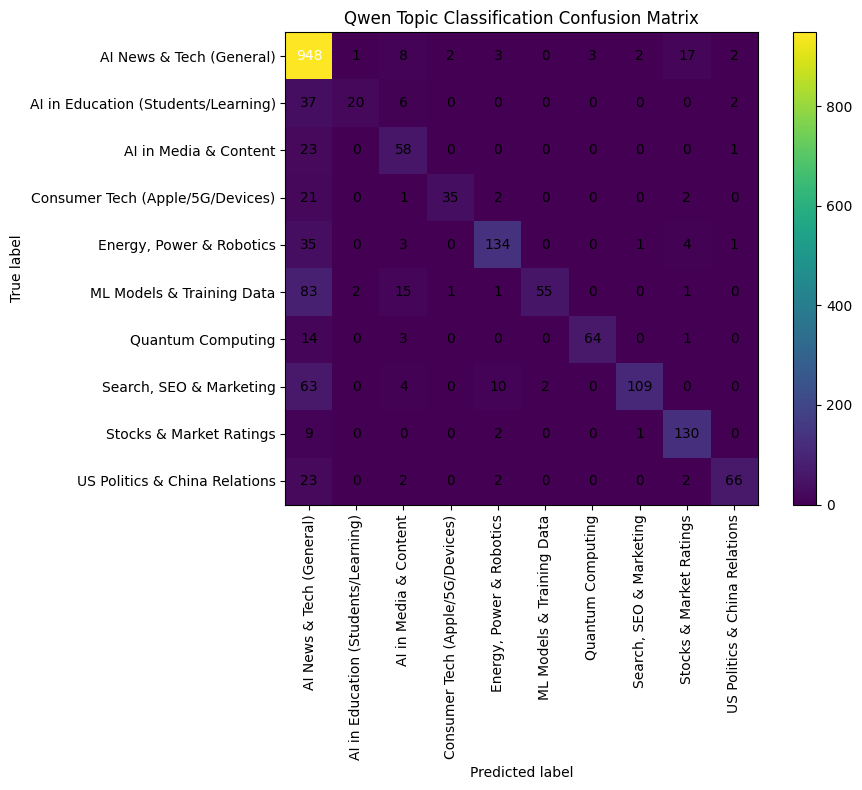

In [41]:
cm = cm_df.values
labels = cm_df.index.tolist()

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest")
plt.title("Qwen Topic Classification Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(labels))
plt.xticks(tick_marks, labels, rotation=90)
plt.yticks(tick_marks, labels)

threshold = cm.max() / 2 if cm.size > 0 else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.2 Training and Validation loss


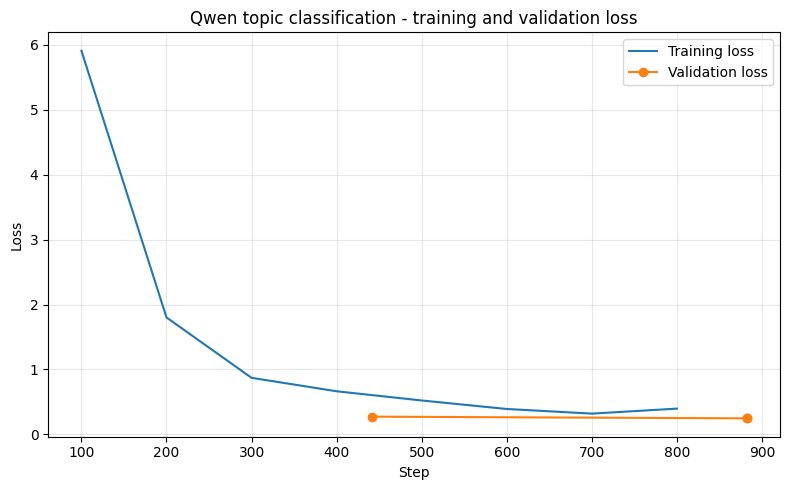

In [45]:

train_logs = pd.read_csv(FINAL_ADAPTER_DIR / "qwen_topic_training_log.csv")

loss_logs = train_logs.dropna(subset=["step", "loss"]).copy()
eval_logs = train_logs.dropna(subset=["epoch", "eval_loss"]).copy()

plt.figure(figsize=(8, 5))
plt.plot(loss_logs["step"], loss_logs["loss"], label="Training loss")
plt.plot(eval_logs["step"], eval_logs["eval_loss"], marker="o", label="Validation loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Qwen topic classification - training and validation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "qwen_training_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()

The loss curves indicate that the fine-tuned Qwen model converged effectively during training. Training loss decreased sharply over the course of optimization, while validation loss remained low and improved slightly from the first to the second epoch. This pattern suggests stable learning and does not indicate obvious overfitting within the two-epoch training schedule.

### 10.3 Macro F1

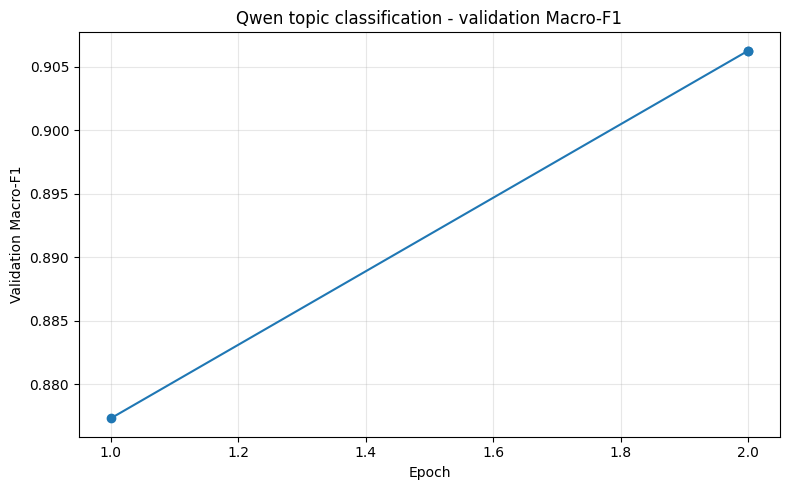

In [46]:
plt.figure(figsize=(8, 5))
plt.plot(eval_logs["epoch"], eval_logs["eval_macro_f1"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("Qwen topic classification - validation Macro-F1")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "qwen_validation_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

The steady increase in validation Macro-F1 suggests that the model continued to benefit from training through the second epoch, with no evidence of performance deterioration on the validation set.



### 10.4 Baseline vs final bar chart

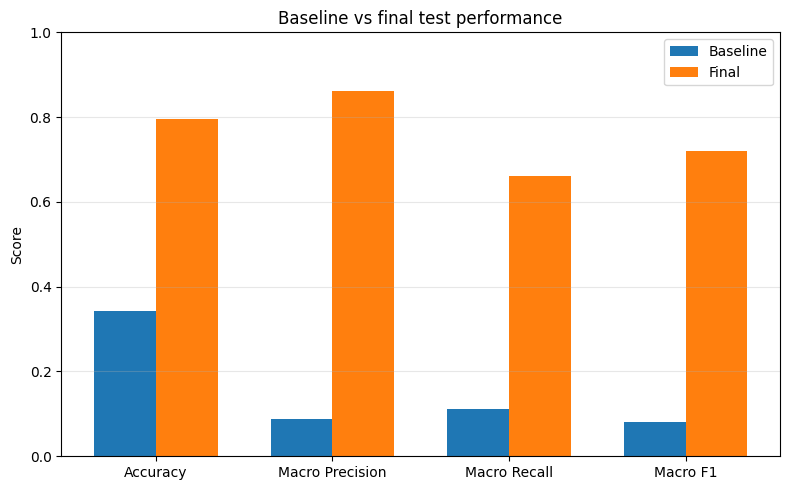

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Use the comparison table you trust most
plot_df = comparison_after_final_df.copy()

metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
x = np.arange(len(metrics))
width = 0.35

baseline_vals = plot_df.iloc[0][metrics].astype(float).values
final_vals = plot_df.iloc[1][metrics].astype(float).values

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, baseline_vals, width, label="Baseline")
plt.bar(x + width/2, final_vals, width, label="Final")

plt.xticks(x, ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"])
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Baseline vs final test performance")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_vs_final_bar_chart.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.5 Normalized confusion matrix (percentages)


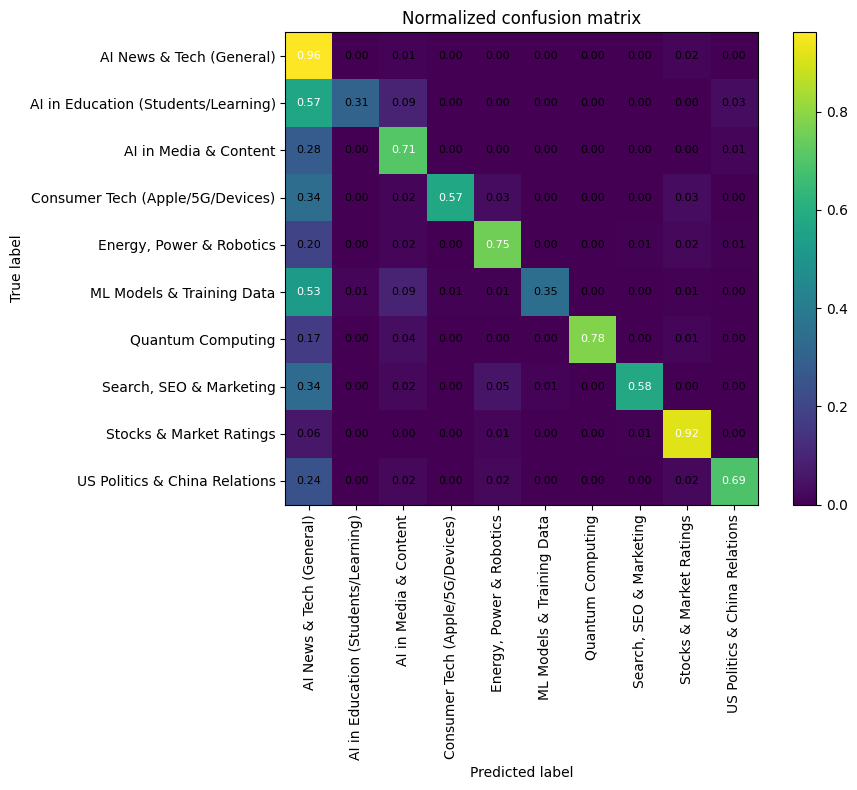

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the final confusion matrix you trust most
cm = cm_df.values.astype(float)

# Row-normalize
row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)

labels = cm_df.index.tolist()

plt.figure(figsize=(10, 8))
plt.imshow(cm_norm, interpolation="nearest")
plt.title("Normalized confusion matrix")
plt.colorbar()

tick_marks = np.arange(len(labels))
plt.xticks(tick_marks, labels, rotation=90)
plt.yticks(tick_marks, labels)

threshold = cm_norm.max() / 2 if cm_norm.size > 0 else 0
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        plt.text(
            j, i, f"{cm_norm[i, j]:.2f}",
            ha="center", va="center",
            color="white" if cm_norm[i, j] > threshold else "black",
            fontsize=8
        )

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "normalized_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

The normalized confusion matrix shows the proportion of documents in each true topic class that were assigned to each predicted class. Diagonal values indicate correct classification rates per class, while off-diagonal values highlight systematic topic confusions. This representation is especially useful when class sizes are imbalanced, as it emphasizes relative rather than absolute performance.